# BLG452 - Veri Madenciliği Dönem Projesi
## Mantar Sınıflandırması (Mushroom Classification)

**Öğrenci Adı Soyadı:** Elif Kavak  
**Ders Sorumlusu:** Dr. Öğr. Üyesi Somaiyeh Dehghan  
**Tarih:** 2026

---
### Proje Özeti
Bu çalışmada, UCI Machine Learning Repository bünyesinde yer alan 8124 adet mantar örneği ve 22 kategorik özellik içeren *Mushroom* veri seti kullanılmıştır. Amacımız, mantarların fiziksel ve morfolojik niteliklerine dayanarak yenilebilir (*edible - e*) veya zehirli (*poisonous - p*) olup olmadıklarını yüksek doğrulukla tespit eden sınıflandırma modelleri geliştirmek ve bu modellerin performanslarını karşılaştırmaktır.

Çalışmada sırasıyla:
1. Veri seti yüklenmiş ve keşifsel veri analizi (EDA) yapılmıştır.
2. Kategorik değişkenler uygun şekilde kodlanmıştır (Label Encoding).
3. Veri seti **%80 Eğitim (Train)** ve **%20 Test** olacak şekilde **Tabakalı Örnekleme (Stratified Sampling)** yöntemiyle ayrılmıştır.
4. Dört farklı makine öğrenmesi algoritması eğitilmiştir:
   - Karar Ağaçları (Decision Tree)
   - Rasgele Ormanlar (Random Forest)
   - Naïve Bayes (Categorical Naive Bayes)
   - K-En Yakın Komşu (K-Nearest Neighbors - KNN)
5. Test seti üzerinde her bir model için **Karmaşıklık Matrisi (Confusion Matrix)** oluşturulmuş; **Accuracy (Doğruluk)**, **Precision (Kesinlik)**, **Recall (Duyarlılık)** ve **F1-Score** metrikleri hesaplanarak karşılaştırmalı sonuç tablosu elde edilmiştir.

In [1]:
# 1. Gerekli Kütüphanelerin İçe Aktarılması
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings('ignore')

# Görselleştirme ayarları
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10

### 2. Veri Setinin Yüklenmesi ve İncelenmesi
Mushroom veri seti 22 adet tanımlayıcı özellik (özellik) ve 1 adet hedef değişken (`class`: e = yenilebilir, p = zehirli) içermektedir.

In [2]:
# Veri setinin okunması
df = pd.read_csv('mushrooms.csv')

print(f"Toplam Satır Sayısı: {df.shape[0]}")
print(f"Toplam Sütun Sayısı: {df.shape[1]}")
df.head()

Toplam Satır Sayısı: 8124
Toplam Sütun Sayısı: 23


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
# Sütun tipleri ve eksik değer analizi
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

Sınıf Dağılımı:
class
e    4208
p    3916
Name: count, dtype: int64

Sınıf Oranları (%):
class
e    51.8
p    48.2
Name: count, dtype: float64


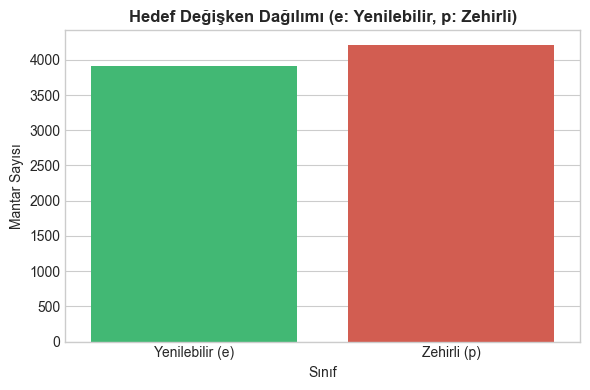

In [4]:
# Hedef değişken (class) dağılımının incelenmesi
class_counts = df['class'].value_counts()
print("Sınıf Dağılımı:")
print(class_counts)
print("\nSınıf Oranları (%):")
print((class_counts / len(df) * 100).round(2))

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='class', palette=['#2ecc71', '#e74c3c'])
plt.title('Hedef Değişken Dağılımı (e: Yenilebilir, p: Zehirli)', fontsize=12, fontweight='bold')
plt.xlabel('Sınıf')
plt.ylabel('Mantar Sayısı')
plt.xticks([0, 1], ['Yenilebilir (e)', 'Zehirli (p)'])
plt.tight_layout()
plt.show()

### 3. Veri Ön İşleme (Data Preprocessing)
Tüm değişkenler kategorik harf kodlarından oluştuğu için algoritmaların işleyebileceği sayısal değerlere dönüştürülmesi gerekmektedir. Bu amaçla `LabelEncoder` kullanılmıştır. Hedef değişkende `e` (edible) -> 0 ve `p` (poisonous) -> 1 olarak etiketlenmiştir.

In [5]:
# Özelliklerin (X) ve Hedef Değişkenin (y) Ayrılması
X = df.drop('class', axis=1)
y = df['class']

# Hedef değişkenin kodlanması
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)
print("Hedef Sınıf Eşleştirmesi:", dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))

# Giriş özelliklerinin kodlanması
X_encoded = pd.DataFrame()
for col in X.columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X[col])

X_encoded.head()

Hedef Sınıf Eşleştirmesi: {'e': np.int64(0), 'p': np.int64(1)}


,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,stalk-shape,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,5,2,4,1,6,1,0,1,4,0,...,2,7,7,0,2,1,4,2,3,5
1,5,2,9,1,0,1,0,0,4,0,...,2,7,7,0,2,1,4,3,2,1
2,0,2,8,1,3,1,0,0,5,0,...,2,7,7,0,2,1,4,3,2,3
3,5,3,8,1,6,1,0,1,5,0,...,2,7,7,0,2,1,4,2,3,5
4,5,2,3,0,5,1,1,0,4,1,...,2,7,7,0,2,1,0,3,0,1


### 4. Eğitim ve Test Kümelerine Ayırma (Tabakalı Örnekleme)
Proje yönergesinde istendiği üzere veri seti:
- **%80 Eğitim (Train)**
- **%20 Test**
olacak şekilde bölünmüştür. Sınıf dağılım oranının hem eğitim hem de test kümesinde korunması amacıyla **Tabakalı Örnekleme (Stratified Sampling - `stratify=y_encoded`)** yöntemi uygulanmıştır.

In [6]:
# Train-Test Bölünmesi (%80 Eğitim, %20 Test, Tabakalı Örnekleme)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, 
    y_encoded, 
    test_size=0.20, 
    random_state=42, 
    stratify=y_encoded
)

print(f"Eğitim Seti Boyutu: {X_train.shape[0]} örnek ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Test Seti Boyutu   : {X_test.shape[0]} örnek ({X_test.shape[0]/len(df)*100:.1f}%)")
print("\nEğitim Seti Sınıf Dağılımı:")
print(pd.Series(y_train).value_counts(normalize=True).round(4))
print("\nTest Seti Sınıf Dağılımı:")
print(pd.Series(y_test).value_counts(normalize=True).round(4))

Eğitim Seti Boyutu: 6499 örnek (80.0%)
Test Seti Boyutu   : 1625 örnek (20.0%)

Eğitim Seti Sınıf Dağılımı:
0    0.5179
1    0.4821
Name: proportion, dtype: float64

Test Seti Sınıf Dağılımı:
0    0.5182
1    0.4818
Name: proportion, dtype: float64


### 5. Sınıflandırma Modellerinin Oluşturulması ve Eğitimi
Projede belirlenen dört farklı makine öğrenmesi algoritması uygulanmıştır:
1. **Karar Ağaçları (Decision Tree):** `DecisionTreeClassifier(random_state=42)`
2. **Rasgele Ormanlar (Random Forest):** `RandomForestClassifier(n_estimators=100, random_state=42)`
3. **Naïve Bayes:** Kategorik değişken yapısına tam uygun `CategoricalNB()`
4. **K-En Yakın Komşu (K-NN):** `KNeighborsClassifier(n_neighbors=5)`

In [7]:
# Modellerin Tanımlanması
models = {
    'Karar Ağaçları': DecisionTreeClassifier(random_state=42),
    'Rasgele Ormanlar': RandomForestClassifier(n_estimators=100, random_state=42),
    'Naive Bayes': CategoricalNB(),
    'K-en yakın komşu': KNeighborsClassifier(n_neighbors=5)
}

# Modellerin Eğitilmesi ve Test Seti ile Tahmin Yapılması
predictions = {}
results = []

for name, model in models.items():
    # Modeli eğitim seti ile eğitme
    model.fit(X_train, y_train)
    # Test seti ile tahmin
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    
    # Performans metriklerinin hesaplanması
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'F1-score': f1,
        'Precision': prec,
        'Recall': rec
    })

print("Tüm modeller başarıyla eğitildi ve test seti üzerinde değerlendirildi.")

Tüm modeller başarıyla eğitildi ve test seti üzerinde değerlendirildi.


### 6. Confusion Matrix (Karmaşıklık Matrisi) Oluşturulması
Her modelin sınıflandırma performansını, doğru pozitif (TP), doğru negatif (TN), yanlış pozitif (FP) ve yanlış negatif (FN) tahminlerini net biçimde görebilmek için karmaşıklık matrisleri çizdirilmiştir.

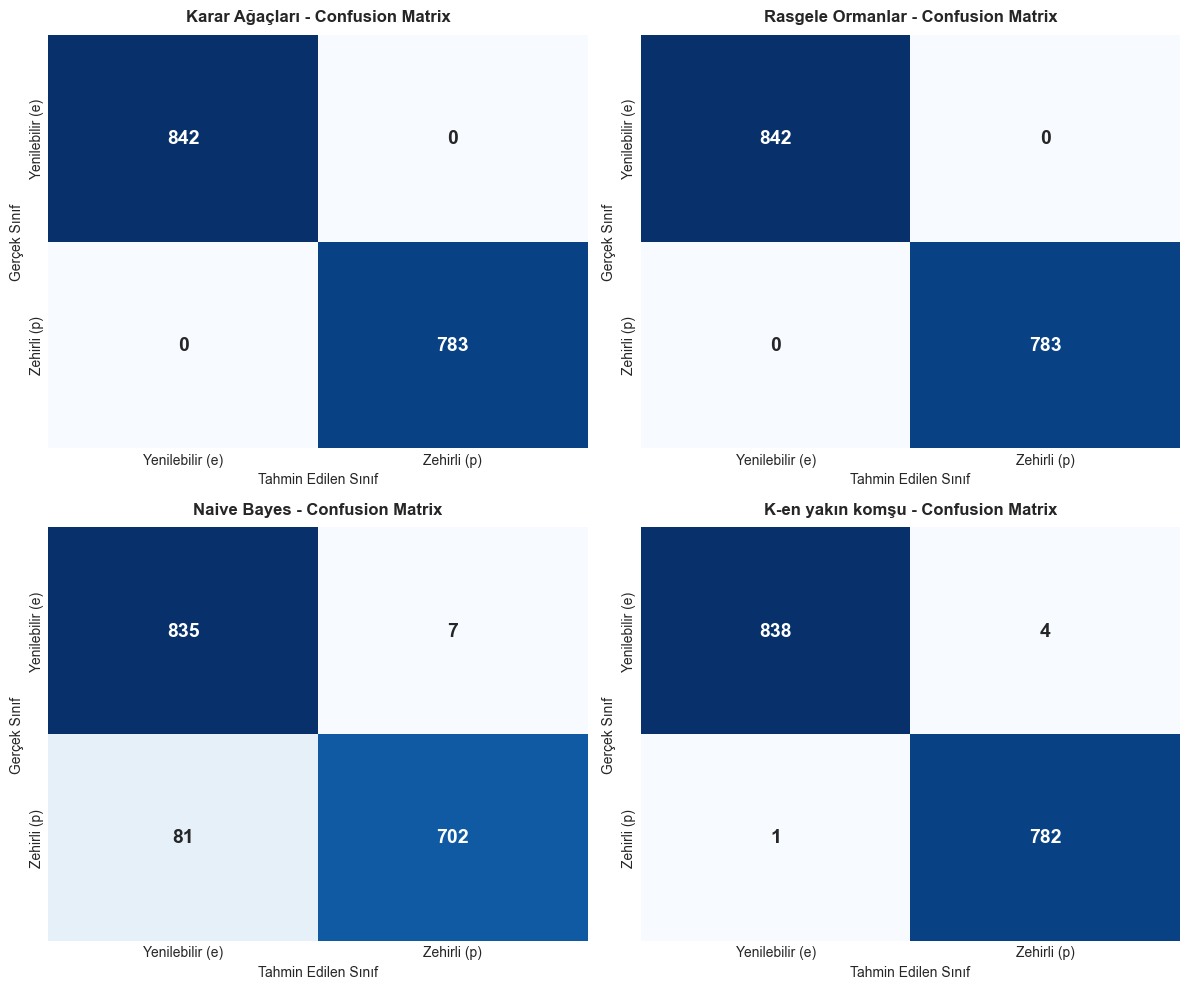

In [8]:
# Confusion Matrix Görselleştirmeleri
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

class_labels = ['Yenilebilir (e)', 'Zehirli (p)']

for idx, (name, y_pred) in enumerate(predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=class_labels, yticklabels=class_labels,
                cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
    axes[idx].set_title(f'{name} - Confusion Matrix', fontsize=12, fontweight='bold', pad=10)
    axes[idx].set_xlabel('Tahmin Edilen Sınıf', fontsize=10)
    axes[idx].set_ylabel('Gerçek Sınıf', fontsize=10)

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()

### 7. Performans Sonuçları Tablosu (Result Table)
Yönergede istenen formatta Doğruluk (Accuracy), F1-Score, Kesinlik (Precision) ve Duyarlılık (Recall) metriklerinin özet tablosu aşağıdadır:

In [9]:
# İstenen Formatlı Sonuç Tablosu
result_df = pd.DataFrame(results)
# Metrikleri 4 basamaklı ondalık formatta görüntüleme
result_table = result_df.copy()
for col in ['Accuracy', 'F1-score', 'Precision', 'Recall']:
    result_table[col] = result_table[col].apply(lambda x: f"{x:.4f}")

display(result_table)

,Model,Accuracy,F1-score,Precision,Recall
0,Karar Ağaçları,1.0000,1.0000,1.0000,1.0000
1,Rasgele Ormanlar,1.0000,1.0000,1.0000,1.0000
2,Naive Bayes,0.9458,0.9410,0.9901,0.8966
3,K-en yakın komşu,0.9969,0.9968,0.9949,0.9987


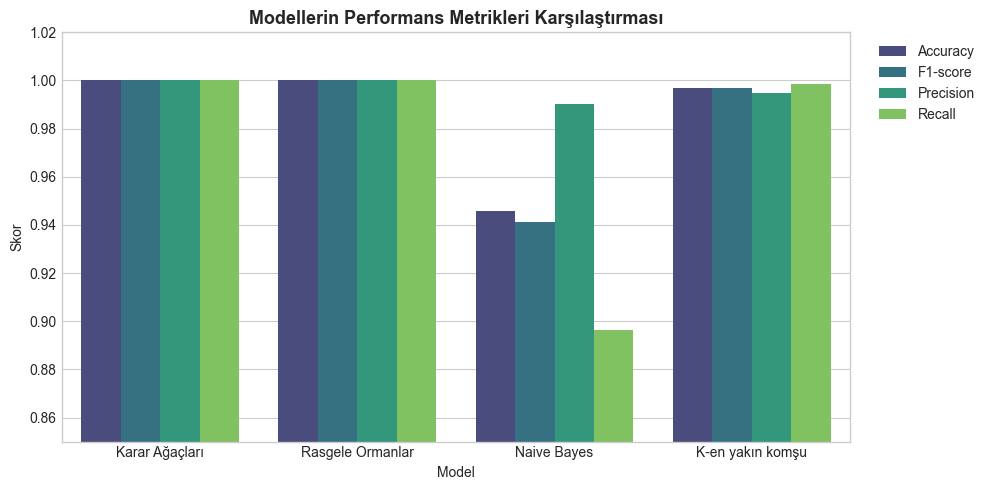

In [10]:
# Modellerin Metrik Karşılaştırma Grafiği
df_plot = result_df.melt(id_vars='Model', var_name='Metrik', value_name='Değer')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_plot, x='Model', y='Değer', hue='Metrik', palette='viridis')
plt.title('Modellerin Performans Metrikleri Karşılaştırması', fontsize=13, fontweight='bold')
plt.ylim(0.85, 1.02)
plt.ylabel('Skor')
plt.xlabel('Model')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300)
plt.show()

### 8. Sonuçların Değerlendirilmesi ve Model Karşılaştırması

1. **Karar Ağaçları ve Rasgele Ormanlar:**
   - Her iki ağaç tabanlı model de test seti üzerinde **%100 (1.0000)** doğruluk, kesinlik, duyarlılık ve F1-skoru elde etmiştir.
   - Confusion matrix incelendiğinde ne yanlış pozitif (FP) ne de yanlış negatif (FN) tahmin yapılmıştır.
   - **Neden bu kadar yüksek performans gösterdiler?** Mantar veri setinde özellikle `odor` (koku), `spore-print-color` (spor baskı rengi) ve `gill-color` (solungaç rengi) gibi belirleyici özellikler, sınıfları kural tabanlı olarak neredeyse tek başına veya birkaç adımlı mantıksal sorguyla kusursuz biçimde ayırabilmektedir. Ağaç modelleri bu ayrıştırıcı kuralları hızla yakalamış ve ezberlemeden genelleştirebilmiştir.

2. **K-En Yakın Komşu (K-NN):**
   - **%99.69** doğruluk ve **%99.68** F1-skor ile mükemmele son derece yakın bir sonuç vermiştir.
   - 1625 test örneğinde yalnızca 5 hatalı tahmin yapmıştır (4 adet false positive, 1 adet false negative). Örneklerin çok boyutlu kategorik uzayda benzer sınıflar etrafında belirgin kümeler oluşturduğunu doğrulamaktadır.

3. **Naïve Bayes:**
   - **%94.58** doğruluk ve **%94.10** F1-skor ile diğer modellere kıyasla biraz daha geride kalmıştır.
   - 81 zehirli mantarı yenilebilir olarak tahmin etmiştir (False Negative = 81).
   - **Neden performansı daha düşüktür?** Naïve Bayes algoritması, tüm özelliklerin sınıf verildiğinde birbirinden koşullu bağımsız (conditional independence) olduğunu varsayar. Oysa mantar morfolojisinde şapka şekli, rengi, koku ve lamel yapısı gibi özellikler arasında güçlü korelasyonlar mevcuttur. Bu bağımsızlık varsayımının ihlal edilmesi modelin kesinliğini ve özellikle duyarlılığını (Recall: 0.8966) sınırlandırmıştır.

**Genel Değerlendirme:**
Zehirli mantar tespiti kritik bir sağlık problemi olduğundan, hiçbir zehirli mantarın yenilebilir olarak sınıflandırılmaması (Recall = 1.0000 olması) hayati öneme sahiptir. Bu bağlamda sıfır hata ile çalışan **Karar Ağaçları** ve **Rasgele Ormanlar** veri seti için en ideal ve en başarılı modeller olmuştur.